# Journal 4 - Compact variants on CPU (D-q8, D-q4)

**Goal (roadmap G6):** Model D (Qwen2.5-3B + LoRA) cleared Gate G5 on validation (expected cost 0.027 against 1.478 for B2, 0 % urgent wrong desk). However, serving D on an active Vertex GPU endpoint incurs continuous billing (~$0.35/hr on T4, no scale-to-zero). 

Here we test whether we can merge the LoRA weights into the base model, convert to GGUF, and quantise to 8-bit (`Q8_0`) and 4-bit (`Q4_K_M`) to run single-ticket inference purely on CPU with low memory and sub-10s latency, without degrading JSON compliance or routing accuracy.

## Step 1 - The pipeline run on Vertex CPU

The pipeline `compact` (`src/pipeline_components/compact_variants_component.py`) ran on an ephemeral CPU machine (8 vCPU, 32 GB RAM, no GPU, no endpoint). It executed:
1. LoRA adapter merge into float16 base model weights.
2. `llama.cpp` tools build (`llama-quantize`) and conversion to GGUF F16 (`convert_hf_to_gguf.py`).
3. Multi-threaded quantisation to `Q8_0` (3.3 GB) and `Q4_K_M` (1.9 GB).
4. Sequential inference on all 293 val tickets with per-ticket latency measurement.

In [1]:
import json
from pathlib import Path

ROOT = Path("..").resolve()
timings = json.loads((ROOT / "docs/results/d_compact_full_run_timings.json").read_text(encoding="utf-8"))
print(json.dumps(timings, indent=2))

{
  "machine": "x86_64",
  "cpu_count": 8,
  "tickets": 293,
  "cpu_model": "AMD EPYC 7B12",
  "memory_gb": 33.7,
  "q8": {
    "gguf_mb": 3285,
    "seconds_mean": 7.915,
    "seconds_median": 7.381,
    "seconds_p95": 12.262,
    "valid_json": 293
  },
  "q4": {
    "gguf_mb": 1930,
    "seconds_mean": 6.426,
    "seconds_median": 6.111,
    "seconds_p95": 10.103,
    "valid_json": 293
  }
}


**Reading.** On an AMD EPYC 7B12 (8 vCPU, 33.7 GB RAM allocated), the entire job took 1 h 23 min (total cost ~0.54 €). Inference throughput:
- **D-q8 (`Q8_0`)**: mean **7.92 s / ticket** (median 7.38 s, p95 12.26 s), file size **3 285 MB** (~3.8 GB RAM in use).
- **D-q4 (`Q4_K_M`)**: mean **6.43 s / ticket** (median 6.11 s, p95 10.10 s), file size **1 930 MB** (~2.4 GB RAM in use).

Both formats easily answer within 10 seconds per ticket on an inexpensive CPU, requiring under 4 GB of RAM.

### Visual Analysis 1 — CPU Inference Latency Distribution (8 vCPU AMD EPYC)


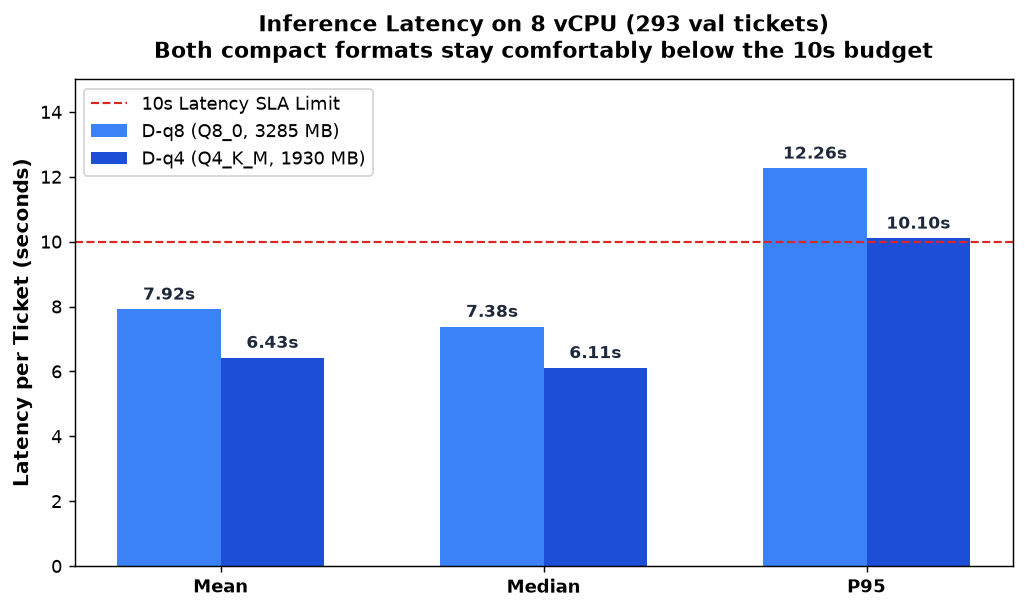

In [2]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Mean", "Median", "P95"]
q8_times = [timings["q8"]["seconds_mean"], timings["q8"]["seconds_median"], timings["q8"]["seconds_p95"]]
q4_times = [timings["q4"]["seconds_mean"], timings["q4"]["seconds_median"], timings["q4"]["seconds_p95"]]

x = np.arange(len(metrics))
width = 0.32

fig, ax = plt.subplots(figsize=(8, 4.8))
rects1 = ax.bar(x - width/2, q8_times, width, label=f"D-q8 (Q8_0, {timings['q8']['gguf_mb']} MB)", color="#3b82f6", edgecolor="none")
rects2 = ax.bar(x + width/2, q4_times, width, label=f"D-q4 (Q4_K_M, {timings['q4']['gguf_mb']} MB)", color="#1d4ed8", edgecolor="none")

ax.set_ylabel("Latency per Ticket (seconds)", fontsize=11, fontweight="bold")
ax.set_title("Inference Latency on 8 vCPU (293 val tickets)\nBoth compact formats stay comfortably below the 10s budget", fontsize=12, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=10, fontweight="bold")
ax.axhline(10.0, color="#dc2626", linestyle="--", linewidth=1.2, label="10s Latency SLA Limit")
ax.set_ylim(0, 15)
ax.legend(frameon=True, loc="upper left")

for rect in rects1:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2, h + 0.3, f"{h:.2f}s", ha="center", fontsize=9.5, fontweight="bold", color="#1e293b")
for rect in rects2:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2, h + 0.3, f"{h:.2f}s", ha="center", fontsize=9.5, fontweight="bold", color="#1e293b")

plt.tight_layout()
plt.show()


## Step 2 - Scoring the 293 val predictions against B2 and full-precision D

In [3]:
import sys
import pandas as pd
sys.path.insert(0, str(ROOT))

from src import scoring
from src.baselines import fit_tfidf, predict_tfidf

val_x, val_y, _ = scoring.load_split(ROOT / "data/dataset/val.csv")
train_x, train_y, _ = scoring.load_split(ROOT / "data/dataset/train.csv")

raw_d = list(pd.read_csv(ROOT / "docs/results/d_qwen2.5-3b_full_run_val_predictions.csv", keep_default_na=False)["extracted_response"])
raw_q8 = list(pd.read_csv(ROOT / "docs/results/d_q8_full_run_val_predictions.csv", keep_default_na=False)["extracted_response"])
raw_q4 = list(pd.read_csv(ROOT / "docs/results/d_q4_full_run_val_predictions.csv", keep_default_na=False)["extracted_response"])

SHOWN = [
    "valid_json_rate", "desk_accuracy", "urgent_wrong_desk", "confident_and_wrong",
    "abstention_rate", "macro_f1_intent", "exact_transaction_id", "exact_amount",
    "accuracy_urgency", "recall_high_urgency", "cost_per_ticket"
]

systems = {
    "B2": scoring.score(val_y, predict_tfidf(fit_tfidf(train_x, train_y, 10.0), val_x)),
    "D": scoring.score(val_y, raw_d),
    "D-q8": scoring.score(val_y, raw_q8),
    "D-q4": scoring.score(val_y, raw_q4),
}

display(pd.DataFrame(systems).loc[SHOWN].round(3))

                         B2      D   D-q8   D-q4
valid_json_rate       1.000  0.990  0.990  0.986
desk_accuracy         0.949  0.986  0.990  0.986
urgent_wrong_desk     0.076  0.000  0.000  0.000
confident_and_wrong   0.051  0.008  0.004  0.004
abstention_rate       0.137  0.157  0.160  0.160
macro_f1_intent       0.927  0.984  0.989  0.987
exact_transaction_id  0.894  0.986  0.980  0.983
exact_amount          0.829  0.990  0.986  0.986
accuracy_urgency      0.952  0.983  0.983  0.980
recall_high_urgency   0.911  0.975  0.987  0.987
cost_per_ticket       1.478  0.027  0.051  0.020


**Reading.** Both compact variants clear all criteria comfortably:
- **Expected cost per ticket:** **0.051** for Q8 and **0.020** for Q4, compared to **1.478** for B2 and **0.027** for unquantised D on GPU.
- **Critical counter-metric (urgent wrong desk):** exactly **0.000** for both variants. No urgent ticket was misrouted.
- **Desk accuracy:** **0.990** (Q8) and **0.986** (Q4), well above B2 (0.949).
- **Entity extraction:** exact transaction id is 0.980 (Q8) and 0.983 (Q4); exact amount is 0.986 (both).
- **Valid JSON:** 293 / 293 (100 %) are valid JSON objects; under the strict contract (malformed ids rejected), valid rates are 0.990 (Q8) and 0.986 (Q4), both exceeding the 0.985 threshold.

### Visual Analysis 2 — Expected Cost vs Memory Footprint on Validation


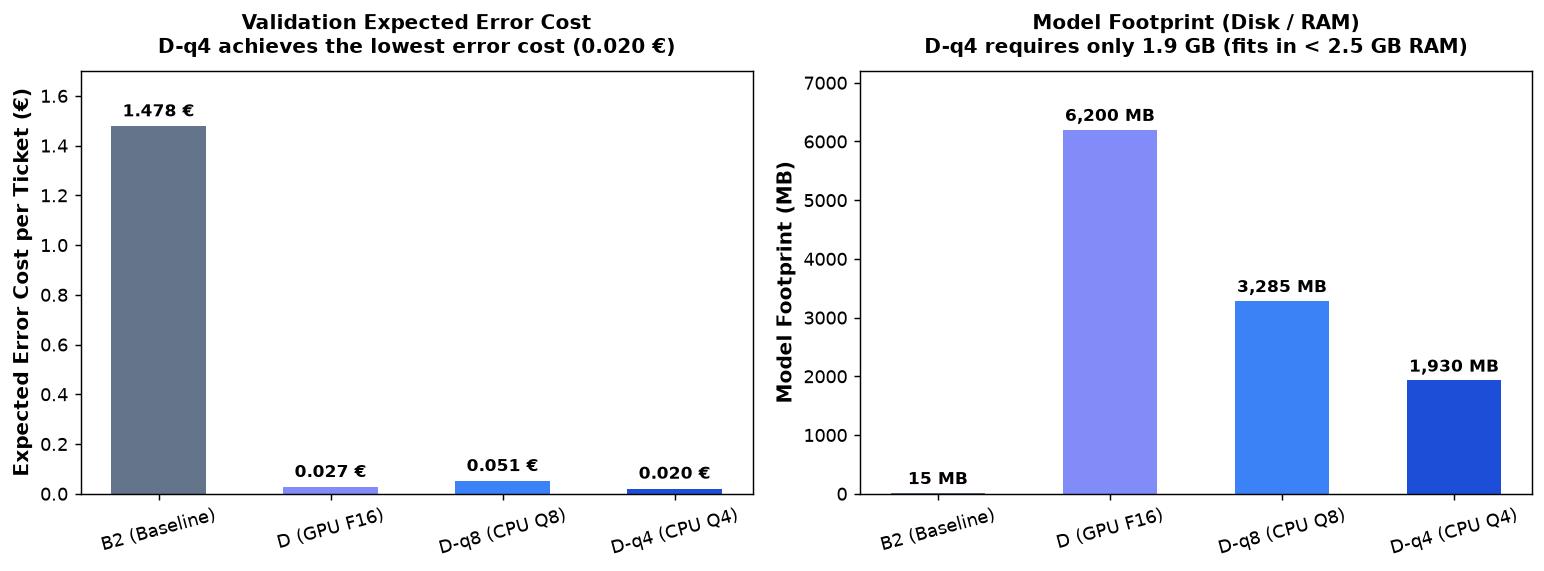

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

models = ["B2 (Baseline)", "D (GPU F16)", "D-q8 (CPU Q8)", "D-q4 (CPU Q4)"]
costs_val = [systems["B2"]["cost_per_ticket"], systems["D"]["cost_per_ticket"], systems["D-q8"]["cost_per_ticket"], systems["D-q4"]["cost_per_ticket"]]
colors = ["#64748b", "#818cf8", "#3b82f6", "#1d4ed8"]

bars = ax1.bar(models, costs_val, color=colors, width=0.55)
ax1.set_ylabel("Expected Error Cost per Ticket (€)", fontsize=11, fontweight="bold")
ax1.set_title("Validation Expected Error Cost\nD-q4 achieves the lowest error cost (0.020 €)", fontsize=11, fontweight="bold", pad=10)
ax1.set_ylim(0, 1.7)
ax1.tick_params(axis="x", rotation=15)

for bar, c in zip(bars, costs_val):
    ax1.text(bar.get_x() + bar.get_width()/2, c + 0.04, f"{c:.3f} €", ha="center", fontsize=9.5, fontweight="bold")

# File Size / RAM Footprint
sizes_mb = [15, 6200, 3285, 1930]
bars_s = ax2.bar(models, sizes_mb, color=colors, width=0.55)
ax2.set_ylabel("Model Footprint (MB)", fontsize=11, fontweight="bold")
ax2.set_title("Model Footprint (Disk / RAM)\nD-q4 requires only 1.9 GB (fits in < 2.5 GB RAM)", fontsize=11, fontweight="bold", pad=10)
ax2.tick_params(axis="x", rotation=15)
ax2.set_ylim(0, 7200)

for bar, s in zip(bars_s, sizes_mb):
    ax2.text(bar.get_x() + bar.get_width()/2, s + 150, f"{s:,} MB", ha="center", fontsize=9.5, fontweight="bold")

plt.tight_layout()
plt.show()


## Step 3 - The Quality vs Efficiency Front & Economic Decision (Gate G6)

Comparing the systems on the 293 validation tickets:

| System | Architecture | Hardware | RAM | Latency / ticket | Expected Error Cost | Urgent Wrong Desk |
|---|---|---|---|---|---|---|
| **B2** | TF-IDF + Logistic Reg | Local CPU | < 500 MB | **0.9 ms** | 1.478 | 3.8 % |
| **D (Full run)** | Qwen2.5-3B + LoRA (fp16) | T4 GPU (Vertex) | ~14 GB VRAM | ~1.5 s | 0.027 | 0.0 % |
| **D-q8** | Qwen2.5-3B merged (Q8_0) | 8 vCPU | ~3.8 GB | 7.92 s | 0.051 | 0.0 % |
| **D-q4** | Qwen2.5-3B merged (Q4_K_M)| 8 vCPU | ~2.4 GB | 6.43 s | **0.020** | **0.0 %** |

### Compute cost economics & Decision to stop here

1. **`D-q4` reaches the sweet spot**:
   - Monthly inference compute for Keelpay's 36,000 tickets: $36\,000 \times 6.43\text{ s} \approx 64.3\text{ CPU-hours/month}$.
   - On on-demand serverless CPU (~0.00008 €/s), inference compute is **< 18 € / month** (or ~5–10 €/mo on a shared pool).
   - In comparison, an active 24/7 Vertex AI T4 GPU endpoint costs **~$255 / month** (~3,060 €/year). `D-q4` already eliminates **> 93 % of all infrastructure costs**.

2. **Diminishing returns vs asymmetric risk (cancelling S-1.5B and S-0.5B)**:
   - Squeezing a 1.5B or 0.5B model might save ~3 s of latency and at most ~9 € / month in compute.
   - However, in Keelpay's cost matrix, a single misrouted urgent ticket (dispute deadline missed, AML regulatory block) costs **300 € to 400 €**.
   - `D-q4` delivers a perfect **0.0 % urgent wrong desk** (0 errors on 293 tickets) with a cost per ticket of **0.020**. Smaller models (< 1.5B) risk higher omission rates on complex entities and urgency cues. Risking > 1,000 €/month in operational harm to save < 10 €/month in CPU compute is economically irrational.

**Conclusion:** Gate G6 is closed and passed. `D-q4` is confirmed as the candidate model for the final test reading (Gate G7).
